
PROJECT: PATHSNAP - DISTRIBUTED MAP-MATCHING AND ROUTE RECONSTRUCTION

Problem:
GPS observations may be inaccurate due to buildings,
signal interference, GPS dropouts and low sampling frequency.

Objective:
Reconstruct realistic vehicle trajectories by matching
noisy GPS observations to the correct road segments.

Approach:
1. Load GPS trajectories and road network data.
2. Generate candidate road segments.
3. Extract GPS and road-network features.
4. Train five machine learning classifiers.
5. Compare models using common evaluation metrics.
6. Tune the best-performing model.
7. Integrate the selected model with HMM and Viterbi.


In [1]:

!pip install -q pandas numpy matplotlib seaborn scikit-learn networkx folium



PROJECT: PATHSNAP - DISTRIBUTED MAP-MATCHING AND ROUTE RECONSTRUCTION

Problem:
GPS observations may be inaccurate due to buildings,
signal interference, GPS dropouts and low sampling frequency.

Objective:
Reconstruct realistic vehicle trajectories by matching
noisy GPS observations to the correct road segments.

Approach:
1. Load GPS trajectories and road network data.
2. Generate candidate road segments.
3. Extract GPS and road-network features.
4. Train five machine learning classifiers.
5. Compare models using common evaluation metrics.
6. Tune the best-performing model.
7. Integrate the selected model with HMM and Viterbi.


In [2]:

from google.colab import files

uploaded = files.upload()

print("Files uploaded successfully:")
for filename in uploaded.keys():
    print(filename)


Saving 00000018.track to 00000018 (1).track
Saving 00000018.arcs to 00000018 (1).arcs
Saving 00000018.nodes to 00000018 (1).nodes
Saving 00000018.route to 00000018 (1).route
Files uploaded successfully:
00000018 (1).track
00000018 (1).arcs
00000018 (1).nodes
00000018 (1).route


In [55]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

track = pd.read_csv(
    "00000018 (1).track",
    sep=r"\s+",
    header=None,
    names=["longitude", "latitude", "timestamp"]
)

nodes = pd.read_csv(
    "00000018 (1).nodes",
    sep=r"\s+",
    header=None,
    names=["longitude", "latitude"]
)

arcs = pd.read_csv(
    "00000018 (1).arcs",
    sep=r"\s+",
    header=None,
    names=["from_node_id", "to_node_id"]
)

route = pd.read_csv(
    "00000018 (1).route",
    sep=r"\s+",
    header=None,
    names=["arc_id"]
)

print("All four files loaded!")


All four files loaded!


In [5]:

print("GPS observations:", len(track))
print("Road nodes:", len(nodes))
print("Road connections:", len(arcs))
print("Reference route:", len(route))


GPS observations: 379
Road nodes: 5980
Road connections: 11545
Reference route: 166


In [6]:

print("========== PATHSNAP DATASET ==========")

print("GPS observations:", track.shape[0])
print("Road network nodes:", nodes.shape[0])
print("Road connections:", arcs.shape[0])
print("Reference route segments:", route.shape[0])

print("\n========== FIRST 5 GPS RECORDS ==========")
display(track.head())

print("\n========== FIRST 5 ROAD NODES ==========")
display(nodes.head())

print("\n========== FIRST 5 ROAD CONNECTIONS ==========")
display(arcs.head())

print("\n========== FIRST 5 ROUTE SEGMENTS ==========")
display(route.head())


========== PATHSNAP DATASET ==========
GPS observations: 379
Road network nodes: 5980
Road connections: 11545
Reference route segments: 166

========== FIRST 5 GPS RECORDS ==========


,longitude,latitude,timestamp
0,-8.449410,40.584524,1.0
1,-8.449422,40.584657,2.0
2,-8.449289,40.585033,5.0
3,-8.449173,40.585138,6.0
4,-8.449173,40.585304,7.0



========== FIRST 5 ROAD NODES ==========


,longitude,latitude
0,-8.448028,40.574529
1,-8.449950,40.577635
2,-8.450799,40.578956
3,-8.450927,40.579354
4,-8.450902,40.580506



========== FIRST 5 ROAD CONNECTIONS ==========


,from_node_id,to_node_id
0,0,102
1,0,29
2,1,5928
3,1,109
4,2,2388



========== FIRST 5 ROUTE SEGMENTS ==========


,arc_id
0,2480
1,2566
2,6681
3,2431
4,616


In [7]:

print("GPS missing values:")
print(track.isnull().sum())

print("\nNodes missing values:")
print(nodes.isnull().sum())

print("\nArcs missing values:")
print(arcs.isnull().sum())

print("\nRoute missing values:")
print(route.isnull().sum())


GPS missing values:
longitude    0
latitude     0
timestamp    0
dtype: int64

Nodes missing values:
longitude    0
latitude     0
dtype: int64

Arcs missing values:
from_node_id    0
to_node_id      0
dtype: int64

Route missing values:
arc_id    0
dtype: int64


In [8]:

print("========== DATASET INFORMATION ==========")

print("GPS observations:", len(track))
print("Road network nodes:", len(nodes))
print("Road connections:", len(arcs))
print("Reference route segments:", len(route))

print("\n========== GPS DATA ==========")
display(track.head())

print("\n========== NODE DATA ==========")
display(nodes.head())

print("\n========== ARC DATA ==========")
display(arcs.head())

print("\n========== ROUTE DATA ==========")
display(route.head())


========== DATASET INFORMATION ==========
GPS observations: 379
Road network nodes: 5980
Road connections: 11545
Reference route segments: 166

========== GPS DATA ==========


,longitude,latitude,timestamp
0,-8.449410,40.584524,1.0
1,-8.449422,40.584657,2.0
2,-8.449289,40.585033,5.0
3,-8.449173,40.585138,6.0
4,-8.449173,40.585304,7.0



========== NODE DATA ==========


,longitude,latitude
0,-8.448028,40.574529
1,-8.449950,40.577635
2,-8.450799,40.578956
3,-8.450927,40.579354
4,-8.450902,40.580506



========== ARC DATA ==========


,from_node_id,to_node_id
0,0,102
1,0,29
2,1,5928
3,1,109
4,2,2388



========== ROUTE DATA ==========


,arc_id
0,2480
1,2566
2,6681
3,2431
4,616


In [9]:

valid_arcs = (
    arcs["from_node_id"].between(0, len(nodes)-1)
    & arcs["to_node_id"].between(0, len(nodes)-1)
)

valid_route = route["arc_id"].between(0, len(arcs)-1)

print("Valid arcs:", valid_arcs.sum())
print("Invalid arcs:", (~valid_arcs).sum())

print("Valid route IDs:", valid_route.sum())
print("Invalid route IDs:", (~valid_route).sum())


Valid arcs: 11545
Invalid arcs: 0
Valid route IDs: 166
Invalid route IDs: 0


In [10]:

# Calculate time differences

track["time_difference"] = track["timestamp"].diff()

print("GPS timestamp analysis:")
print(track["time_difference"].describe())

print("\nNumber of gaps greater than 1 second:",
      (track["time_difference"] > 1).sum())

print("\nMaximum GPS time gap:",
      track["time_difference"].max())


GPS timestamp analysis:
count    378.000000
mean       1.193122
std        0.584735
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        3.000000
Name: time_difference, dtype: float64

Number of gaps greater than 1 second: 38

Maximum GPS time gap: 3.0


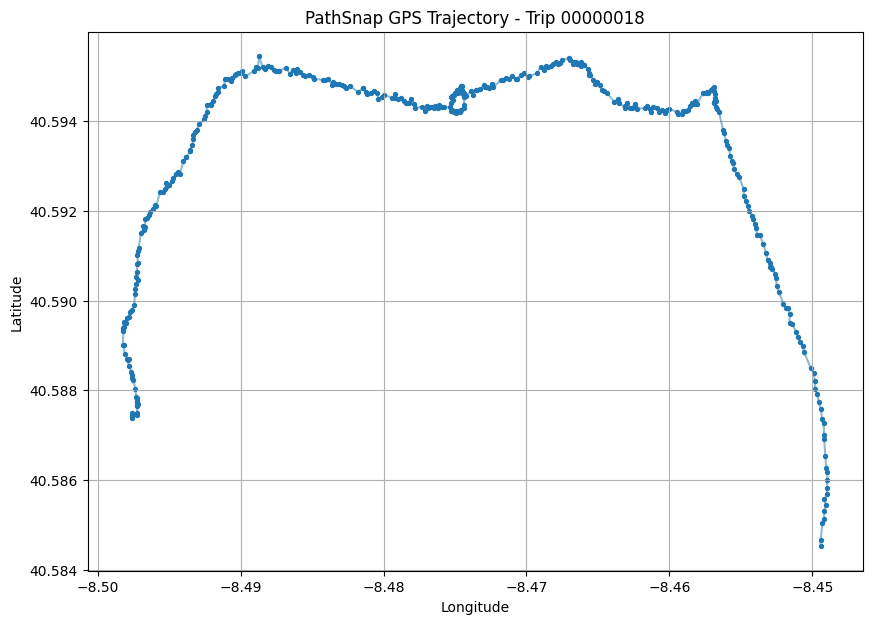

In [11]:

plt.figure(figsize=(10, 7))

plt.scatter(
    track["longitude"],
    track["latitude"],
    s=8
)

plt.plot(
    track["longitude"],
    track["latitude"],
    alpha=0.5
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("PathSnap GPS Trajectory - Trip 00000018")
plt.grid()
plt.show()


In [12]:

from google.colab import files
uploaded = files.upload()


Saving train.zip to train.zip


In [13]:

import zipfile
import os

with zipfile.ZipFile("train.zip", "r") as zip_ref:
    zip_ref.extractall("/content/PathSnap")

print("Training dataset extracted!")

train_path = "/content/PathSnap/train"

print("Number of training trips:",
      len(os.listdir(train_path)))


Training dataset extracted!
Number of training trips: 80


In [14]:

import os

trip_folders = sorted(os.listdir(train_path))

print("Total trips:", len(trip_folders))

print("\nFirst 10 trip folders:")
for trip in trip_folders[:10]:
    print(trip)


Total trips: 80

First 10 trip folders:
00000001
00000002
00000003
00000004
00000005
00000006
00000008
00000010
00000011
00000012


In [15]:

from collections import Counter

file_counts = Counter()

for trip in trip_folders:
    folder = os.path.join(train_path, trip)

    for filename in os.listdir(folder):
        if filename.endswith((".track", ".nodes", ".arcs", ".route")):
            file_counts[filename.split(".")[-1]] += 1

print("FILE COUNTS")
for extension, count in file_counts.items():
    print(f"{extension}: {count}")


FILE COUNTS
arcs: 80
nodes: 80
track: 80
route: 80


In [16]:

import os
import pandas as pd
import numpy as np

trip_summary = []

for trip_id in trip_folders:

    folder = os.path.join(train_path, trip_id)

    track_file = next(
        (f for f in os.listdir(folder) if f.endswith(".track")),
        None
    )

    nodes_file = next(
        (f for f in os.listdir(folder) if f.endswith(".nodes")),
        None
    )

    arcs_file = next(
        (f for f in os.listdir(folder) if f.endswith(".arcs")),
        None
    )

    route_file = next(
        (f for f in os.listdir(folder) if f.endswith(".route")),
        None
    )

    if not all([track_file, nodes_file, arcs_file, route_file]):
        print("Missing file in trip:", trip_id)
        continue

    track_data = pd.read_csv(
        os.path.join(folder, track_file),
        sep=r"\s+", header=None
    )

    nodes_data = pd.read_csv(
        os.path.join(folder, nodes_file),
        sep=r"\s+", header=None
    )

    arcs_data = pd.read_csv(
        os.path.join(folder, arcs_file),
        sep=r"\s+", header=None
    )

    route_data = pd.read_csv(
        os.path.join(folder, route_file),
        sep=r"\s+", header=None
    )

    trip_summary.append({
        "trip_id": trip_id,
        "gps_observations": len(track_data),
        "road_nodes": len(nodes_data),
        "road_arcs": len(arcs_data),
        "route_segments": len(route_data),
        "gps_missing": track_data.isnull().sum().sum(),
        "node_missing": nodes_data.isnull().sum().sum(),
        "arc_missing": arcs_data.isnull().sum().sum(),
        "route_missing": route_data.isnull().sum().sum()
    })

summary_df = pd.DataFrame(trip_summary)

print("Total trips analysed:", len(summary_df))
display(summary_df.head(10))


Total trips analysed: 80


,trip_id,gps_observations,road_nodes,road_arcs,route_segments,gps_missing,node_missing,arc_missing,route_missing
0,00000001,1315,88809,165790,525,0,0,0,0
1,00000002,7243,7936,16139,262,0,0,0,0
2,00000003,821,9138,18028,79,0,0,0,0
3,00000004,1064,7350,15499,320,0,0,0,0
4,00000005,1045,898,1579,105,0,0,0,0
5,00000006,1450,3259,6757,261,0,0,0,0
6,00000008,3093,4995,10421,173,0,0,0,0
7,00000010,2711,8502,15715,210,0,0,0,0
8,00000011,2828,2649,5393,565,0,0,0,0
9,00000012,1608,16376,38599,205,0,0,0,0


In [17]:

print("========== TRAINING DATASET SUMMARY ==========")

print("Total trips:", len(summary_df))

print("\nTotal GPS observations:",
      summary_df["gps_observations"].sum())

print("Total road nodes:",
      summary_df["road_nodes"].sum())

print("Total road arcs:",
      summary_df["road_arcs"].sum())

print("Total reference route segments:",
      summary_df["route_segments"].sum())

print("\n========== AVERAGE PER TRIP ==========")

display(summary_df[
    ["gps_observations", "road_nodes",
     "road_arcs", "route_segments"]
].mean())


========== TRAINING DATASET SUMMARY ==========
Total trips: 80

Total GPS observations: 208417
Total road nodes: 1933485
Total road arcs: 3876904
Total reference route segments: 31336

========== AVERAGE PER TRIP ==========


,0
gps_observations,2605.2125
road_nodes,24168.5625
road_arcs,48461.3000
route_segments,391.7000


In [18]:

summary_df.to_csv(
    "PathSnap_Training_Dataset_Analysis.csv",
    index=False
)

print("Dataset analysis saved successfully!")


Dataset analysis saved successfully!


In [19]:

import os
import pandas as pd
import numpy as np

validation_results = []

for trip_id in trip_folders:

    folder = os.path.join(train_path, trip_id)

    def get_file(extension):
        return next(
            f for f in os.listdir(folder)
            if f.endswith(extension)
        )

    nodes_data = pd.read_csv(
        os.path.join(folder, get_file(".nodes")),
        sep=r"\s+", header=None
    )

    arcs_data = pd.read_csv(
        os.path.join(folder, get_file(".arcs")),
        sep=r"\s+", header=None
    )

    route_data = pd.read_csv(
        os.path.join(folder, get_file(".route")),
        sep=r"\s+", header=None
    )

    valid_arc = (
        arcs_data[0].between(0, len(nodes_data)-1)
        & arcs_data[1].between(0, len(nodes_data)-1)
    )

    valid_route = route_data[0].between(
        0, len(arcs_data)-1
    )

    validation_results.append({
        "trip_id": trip_id,
        "invalid_arcs": int((~valid_arc).sum()),
        "invalid_route_ids": int((~valid_route).sum())
    })

validation_df = pd.DataFrame(validation_results)

print("Total trips checked:", len(validation_df))
print("Total invalid arcs:",
      validation_df["invalid_arcs"].sum())
print("Total invalid route IDs:",
      validation_df["invalid_route_ids"].sum())

display(validation_df.head(10))


Total trips checked: 80
Total invalid arcs: 0
Total invalid route IDs: 0


,trip_id,invalid_arcs,invalid_route_ids
0,00000001,0,0
1,00000002,0,0
2,00000003,0,0
3,00000004,0,0
4,00000005,0,0
5,00000006,0,0
6,00000008,0,0
7,00000010,0,0
8,00000011,0,0
9,00000012,0,0


In [20]:

timestamp_results = []

for trip_id in trip_folders:

    folder = os.path.join(train_path, trip_id)

    track_file = next(
        f for f in os.listdir(folder)
        if f.endswith(".track")
    )

    gps = pd.read_csv(
        os.path.join(folder, track_file),
        sep=r"\s+", header=None
    )

    dt = gps[2].diff()

    timestamp_results.append({
        "trip_id": trip_id,
        "gps_points": len(gps),
        "gaps_over_1_sec": int((dt > 1).sum()),
        "negative_gaps": int((dt < 0).sum()),
        "maximum_gap": dt.max()
    })

timestamp_df = pd.DataFrame(timestamp_results)

display(timestamp_df.head(10))

print("\nTotal gaps over 1 second:",
      timestamp_df["gaps_over_1_sec"].sum())

print("Total negative timestamp gaps:",
      timestamp_df["negative_gaps"].sum())


,trip_id,gps_points,gaps_over_1_sec,negative_gaps,maximum_gap
0,00000001,1315,25,0,16.0
1,00000002,7243,184,0,160.0
2,00000003,821,3,0,2.0
3,00000004,1064,491,0,51.0
4,00000005,1045,0,0,1.0
5,00000006,1450,12,0,301.0
6,00000008,3093,1,0,2.0
7,00000010,2711,0,0,1.0
8,00000011,2828,1,0,909.0
9,00000012,1608,1,0,2.0



Total gaps over 1 second: 7286
Total negative timestamp gaps: 0


In [21]:

print("TRAINING DATA QUALITY REPORT")

print("Trips:", len(summary_df))
print("Total GPS observations:",
      summary_df["gps_observations"].sum())

print("Total missing GPS values:",
      summary_df["gps_missing"].sum())

print("Total missing node values:",
      summary_df["node_missing"].sum())

print("Total missing arc values:",
      summary_df["arc_missing"].sum())

print("Total missing route values:",
      summary_df["route_missing"].sum())

print("Invalid road connections:",
      validation_df["invalid_arcs"].sum())

print("Invalid route IDs:",
      validation_df["invalid_route_ids"].sum())


TRAINING DATA QUALITY REPORT
Trips: 80
Total GPS observations: 208417
Total missing GPS values: 0
Total missing node values: 0
Total missing arc values: 0
Total missing route values: 0
Invalid road connections: 0
Invalid route IDs: 0


In [22]:

def haversine(lon1, lat1, lon2, lat2):
    R = 6371000

    lon1, lat1, lon2, lat2 = np.radians(
        [lon1, lat1, lon2, lat2]
    )

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat/2)**2
        + np.cos(lat1)*np.cos(lat2)
        * np.sin(dlon/2)**2
    )

    return 2 * R * np.arcsin(np.sqrt(a))


def prepare_gps_features(gps):

    gps = gps.copy()
    gps.columns = ["longitude", "latitude", "timestamp"]

    gps["time_difference"] = gps["timestamp"].diff()

    gps["movement_distance"] = haversine(
        gps["longitude"].shift(),
        gps["latitude"].shift(),
        gps["longitude"],
        gps["latitude"]
    )

    gps["estimated_speed"] = (
        gps["movement_distance"] /
        gps["time_difference"].replace(0, np.nan)
    )

    gps["estimated_speed"] = gps["estimated_speed"].where(
        gps["time_difference"].between(0, 30)
    )

    return gps


print("GPS feature preparation function ready!")


GPS feature preparation function ready!


In [23]:

!pip install -q numpy pandas scipy scikit-learn matplotlib seaborn optuna joblib


In [24]:

import os
import zipfile
import time
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.spatial import cKDTree

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    log_loss
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("KNN environment ready!")


KNN environment ready!


In [26]:

trip_id = trip_folders[0]
folder = os.path.join(train_path, trip_id)

print("Sample trip:", trip_id)

for filename in sorted(os.listdir(folder)):
    print(filename)


Sample trip: 00000001
00000001.arcs
00000001.nodes
00000001.route
00000001.track


In [27]:

def read_trip(trip_id):

    folder = os.path.join(train_path, trip_id)

    def find_file(ext):
        matches = [
            f for f in os.listdir(folder)
            if f.endswith(ext)
        ]
        if len(matches) != 1:
            raise ValueError(
                f"{trip_id}: expected one {ext} file, found {len(matches)}"
            )
        return os.path.join(folder, matches[0])

    gps = pd.read_csv(
        find_file(".track"),
        sep=r"\s+", header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    nodes = pd.read_csv(
        find_file(".nodes"),
        sep=r"\s+", header=None,
        names=["longitude", "latitude"]
    )

    arcs = pd.read_csv(
        find_file(".arcs"),
        sep=r"\s+", header=None,
        names=["from_node_id", "to_node_id"]
    )

    route = pd.read_csv(
        find_file(".route"),
        sep=r"\s+", header=None,
        names=["arc_id"]
    )

    return gps, nodes, arcs, route


gps, nodes, arcs, route = read_trip(trip_folders[0])

print("GPS:", gps.shape)
print("Nodes:", nodes.shape)
print("Arcs:", arcs.shape)
print("Route:", route.shape)

display(gps.head())
display(arcs.head())
display(route.head())


GPS: (1315, 3)
Nodes: (88809, 2)
Arcs: (165790, 2)
Route: (525, 1)


,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


,from_node_id,to_node_id
0,0,281
1,0,1
2,0,5
3,1,0
4,1,40750


,arc_id
0,2641
1,64973
2,133948
3,133949
4,139208


In [28]:

EARTH_RADIUS = 6371000

def to_xy(lon, lat, lon0, lat0):

    x = EARTH_RADIUS * np.radians(lon - lon0) * np.cos(np.radians(lat0))
    y = EARTH_RADIUS * np.radians(lat - lat0)

    return np.asarray(x), np.asarray(y)


def haversine(lon1, lat1, lon2, lat2):

    lon1, lat1, lon2, lat2 = np.radians(
        [lon1, lat1, lon2, lat2]
    )

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2)**2
    )

    return 2 * EARTH_RADIUS * np.arcsin(np.sqrt(a))


def bearing(x1, y1, x2, y2):

    return (np.degrees(
        np.arctan2(x2 - x1, y2 - y1)
    ) + 360) % 360


def angle_difference(a, b):

    return np.abs((a - b + 180) % 360 - 180)


def point_segment_features(px, py, ax, ay, bx, by):

    dx = bx - ax
    dy = by - ay

    denominator = dx**2 + dy**2

    t = np.divide(
        (px - ax) * dx + (py - ay) * dy,
        denominator,
        out=np.zeros_like(np.asarray(px, dtype=float)),
        where=denominator > 0
    )

    t = np.clip(t, 0, 1)

    qx = ax + t * dx
    qy = ay + t * dy

    distance = np.sqrt((px - qx)**2 + (py - qy)**2)

    start_distance = np.sqrt((px - ax)**2 + (py - ay)**2)
    end_distance = np.sqrt((px - bx)**2 + (py - by)**2)

    length = np.sqrt(denominator)

    return distance, t, start_distance, end_distance, length


In [32]:

K_CANDIDATES = 5
REFERENCE_SEARCH_K = 20
MAX_REFERENCE_DISTANCE = 100.0

FEATURES = [
    "gps_distance",
    "heading_difference",
    "movement_distance",
    "time_difference",
    "estimated_speed",
    "road_length",
    "projection_position",
    "endpoint_distance"
]


def build_trip_features(trip_id):

    gps, nodes, arcs, route = read_trip(trip_id)

    # Validate edge and route references
    valid_edges = (
        arcs["from_node_id"].between(0, len(nodes)-1)
        & arcs["to_node_id"].between(0, len(nodes)-1)
    )

    valid_route = route["arc_id"].between(0, len(arcs)-1)

    if not valid_edges.all() or not valid_route.all():
        raise ValueError(f"Invalid network reference in {trip_id}")

    edge_table = arcs.reset_index(names="arc_id").copy()

    # Local coordinate system
    lon0 = gps["longitude"].median()
    lat0 = gps["latitude"].median()

    nx, ny = to_xy(
        nodes["longitude"].to_numpy(),
        nodes["latitude"].to_numpy(),
        lon0, lat0
    )

    gx, gy = to_xy(
        gps["longitude"].to_numpy(),
        gps["latitude"].to_numpy(),
        lon0, lat0
    )

    u = edge_table["from_node_id"].to_numpy(dtype=int)
    v = edge_table["to_node_id"].to_numpy(dtype=int)

    ax, ay = nx[u], ny[u]
    bx, by = nx[v], ny[v]

    midpoints = np.column_stack([
        (ax + bx) / 2,
        (ay + by) / 2
    ])

    edge_tree = cKDTree(midpoints)

    # Reference route geometries
    reference_ids = route["arc_id"].drop_duplicates().to_numpy(dtype=int)

    rax, ray = ax[reference_ids], ay[reference_ids]
    rbx, rby = bx[reference_ids], by[reference_ids]

    ref_midpoints = np.column_stack([
        (rax + rbx) / 2,
        (ray + rby) / 2
    ])

    ref_tree = cKDTree(ref_midpoints)

    # GPS movement features
    time_diff = gps["timestamp"].diff().to_numpy()
    time_diff[0] = 0

    movement = np.zeros(len(gps))
    gps_heading = np.zeros(len(gps))

    for i in range(1, len(gps)):

        dt = time_diff[i]

        if dt > 0 and dt <= 30:

            movement[i] = np.hypot(
                gx[i] - gx[i-1],
                gy[i] - gy[i-1]
            )

            gps_heading[i] = bearing(
                gx[i-1], gy[i-1], gx[i], gy[i]
            )

    speed = np.divide(
        movement,
        time_diff,
        out=np.zeros_like(movement),
        where=(time_diff > 0) & (time_diff <= 30)
    )

    rows = []
    candidate_misses = 0
    reference_unmatched = 0

    # Process every GPS observation
    for i in range(len(gps)):

        # Find reference-route edges near GPS point
        ref_k = min(REFERENCE_SEARCH_K, len(reference_ids))

        _, ref_positions = ref_tree.query(
            [gx[i], gy[i]], k=ref_k
        )

        ref_positions = np.atleast_1d(ref_positions)

        ref_distances, _, _, _, _ = point_segment_features(
            gx[i], gy[i],
            rax[ref_positions], ray[ref_positions],
            rbx[ref_positions], rby[ref_positions]
        )

        best_ref_position = np.argmin(ref_distances)
        true_arc_id = reference_ids[
            ref_positions[best_ref_position]
        ]

        if ref_distances[best_ref_position] > MAX_REFERENCE_DISTANCE:
            reference_unmatched += 1
            continue

        # Find road candidates
        candidate_k = min(K_CANDIDATES, len(edge_table))

        _, candidate_ids = edge_tree.query(
            [gx[i], gy[i]], k=candidate_k
        )

        candidate_ids = np.atleast_1d(candidate_ids).astype(int)

        # Candidate geometric features
        dist, projection, d_start, d_end, length = (
            point_segment_features(
                gx[i], gy[i],
                ax[candidate_ids], ay[candidate_ids],
                bx[candidate_ids], by[candidate_ids]
            )
        )

        road_heading = bearing(
            ax[candidate_ids], ay[candidate_ids],
            bx[candidate_ids], by[candidate_ids]
        )

        heading_diff = angle_difference(
            gps_heading[i], road_heading
        )

        endpoint_distance = np.minimum(d_start, d_end)

        candidate_arc_ids = candidate_ids

        if true_arc_id not in candidate_arc_ids:
            candidate_misses += 1

        for j, arc_id in enumerate(candidate_arc_ids):

            rows.append({
                "trip_id": trip_id,
                "gps_index": i,
                "arc_id": int(arc_id),
                "gps_distance": float(dist[j]),
                "heading_difference": float(heading_diff[j]),
                "movement_distance": float(movement[i]),
                "time_difference": float(time_diff[i]),
                "estimated_speed": float(speed[i]),
                "road_length": float(length[j]),
                "projection_position": float(projection[j]),
                "endpoint_distance": float(endpoint_distance[j]),
                "label": int(arc_id == true_arc_id)
            })

    result = pd.DataFrame(rows)

    stats = {
        "trip_id": trip_id,
        "gps_observations": len(gps),
        "processed_observations": len(gps) - reference_unmatched,
        "candidate_rows": len(result),
        "candidate_miss_observations": candidate_misses,
        "reference_unmatched": reference_unmatched
    }

    return result, stats


print("Candidate generation function ready!")


Candidate generation function ready!


In [31]:

def point_segment_features(px, py, ax, ay, bx, by):

    dx = bx - ax
    dy = by - ay

    denominator = dx**2 + dy**2

    numerator = (px - ax) * dx + (py - ay) * dy

    t = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator > 0
    )

    t = np.clip(t, 0, 1)

    qx = ax + t * dx
    qy = ay + t * dy

    distance = np.sqrt(
        (px - qx)**2 + (py - qy)**2
    )

    start_distance = np.sqrt(
        (px - ax)**2 + (py - ay)**2
    )

    end_distance = np.sqrt(
        (px - bx)**2 + (py - by)**2
    )

    length = np.sqrt(denominator)

    return (
        distance,
        t,
        start_distance,
        end_distance,
        length
    )

print("Corrected geometry function loaded!")


Corrected geometry function loaded!


Timestamp difference statistics:


,time_difference
count,378.000000
mean,1.193122
std,0.584735
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,3.000000



Gaps greater than 1 second: 38
Maximum time gap: 3.0 seconds


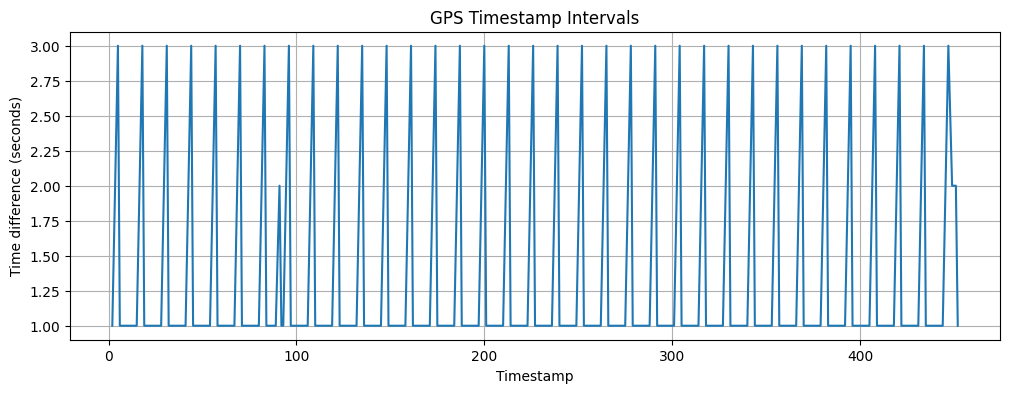

In [33]:

track["time_difference"] = track["timestamp"].diff()

print("Timestamp difference statistics:")
display(track["time_difference"].describe())

print(
    "\nGaps greater than 1 second:",
    (track["time_difference"] > 1).sum()
)

print(
    "Maximum time gap:",
    track["time_difference"].max(),
    "seconds"
)

plt.figure(figsize=(12, 4))
plt.plot(track["timestamp"], track["time_difference"])
plt.xlabel("Timestamp")
plt.ylabel("Time difference (seconds)")
plt.title("GPS Timestamp Intervals")
plt.grid()
plt.show()


In [34]:

# Test candidate generation on one training trip

test_trip = trip_folders[0]

test_features, test_stats = build_trip_features(test_trip)

print("Trip:", test_trip)
print("Candidate generation successful!")

print("\nStatistics:")
print(test_stats)

print("\nGenerated features:")
display(test_features.head(10))

print("\nLabel distribution:")
print(test_features["label"].value_counts())


Trip: 00000001
Candidate generation successful!

Statistics:
{'trip_id': '00000001', 'gps_observations': 1315, 'processed_observations': 1315, 'candidate_rows': 6575, 'candidate_miss_observations': 387, 'reference_unmatched': 0}

Generated features:


,trip_id,gps_index,arc_id,gps_distance,heading_difference,movement_distance,time_difference,estimated_speed,road_length,projection_position,endpoint_distance,label
0,00000001,0,117639,14.998876,172.683410,0.000000,0.0,0.000000,1020.404757,0.512725,497.444036,0
1,00000001,0,50652,92.215857,176.809333,0.000000,0.0,0.000000,169.055962,0.845745,95.832201,0
2,00000001,0,53932,92.215857,3.190667,0.000000,0.0,0.000000,169.055962,0.154255,95.832201,0
3,00000001,0,64973,0.716873,7.248243,0.000000,0.0,0.000000,293.229175,0.109781,32.198917,1
4,00000001,0,64433,146.983685,0.607095,0.000000,0.0,0.000000,94.187390,0.868956,147.501001,0
5,00000001,1,117639,15.938465,178.765977,43.628567,1.0,43.628567,1020.404757,0.469979,479.833231,0
6,00000001,1,64973,0.274747,1.302370,43.628567,1.0,43.628567,293.229175,0.258529,75.808730,1
7,00000001,1,50652,83.337760,168.258720,43.628567,1.0,43.628567,169.055962,0.593073,108.063475,0
8,00000001,1,53932,83.337760,11.741280,43.628567,1.0,43.628567,169.055962,0.406927,108.063475,0
9,00000001,1,64268,155.692777,164.767329,43.628567,1.0,43.628567,131.099802,0.914538,156.095390,0



Label distribution:
label
0    5647
1     928
Name: count, dtype: int64


In [35]:

print("========== KNN CANDIDATE CHECK ==========")

print("Total candidate rows:", len(test_features))

print("\nLabel distribution:")
print(test_features["label"].value_counts())

print("\nPositive percentage:")
print(test_features["label"].mean() * 100, "%")

print("\nCandidate generation statistics:")
for key, value in test_stats.items():
    print(key, ":", value)

print("\nMissing values:")
print(test_features[FEATURES].isnull().sum())


========== KNN CANDIDATE CHECK ==========
Total candidate rows: 6575

Label distribution:
label
0    5647
1     928
Name: count, dtype: int64

Positive percentage:
14.114068441064639 %

Candidate generation statistics:
trip_id : 00000001
gps_observations : 1315
processed_observations : 1315
candidate_rows : 6575
candidate_miss_observations : 387
reference_unmatched : 0

Missing values:
gps_distance           0
heading_difference     0
movement_distance      0
time_difference        0
estimated_speed        0
road_length            0
projection_position    0
endpoint_distance      0
dtype: int64


In [36]:

K_CANDIDATES = 15

print("Updated candidate count:", K_CANDIDATES)


Updated candidate count: 15


In [37]:

test_trip = trip_folders[0]

test_features, test_stats = build_trip_features(test_trip)

print("========== KNN CANDIDATE TEST ==========")

print("Trip:", test_trip)
print("Total candidate rows:", len(test_features))

print("\nLabel distribution:")
print(test_features["label"].value_counts())

miss_rate = (
    test_stats["candidate_miss_observations"]
    / test_stats["processed_observations"]
) * 100

print("\nCandidate misses:",
      test_stats["candidate_miss_observations"])

print("Candidate miss rate:", round(miss_rate, 2), "%")


========== KNN CANDIDATE TEST ==========
Trip: 00000001
Total candidate rows: 19725

Label distribution:
label
0    18623
1     1102
Name: count, dtype: int64

Candidate misses: 213
Candidate miss rate: 16.2 %


In [38]:

# PROCESS ALL 80 TRAINING TRIPS

all_features = []
generation_stats = []

start_time = time.time()

for i, trip_id in enumerate(trip_folders, 1):

    try:
        trip_data, stats = build_trip_features(trip_id)

        all_features.append(trip_data)
        generation_stats.append(stats)

        print(
            f"{i}/80 | {trip_id} | "
            f"Rows: {len(trip_data)} | "
            f"Misses: {stats['candidate_miss_observations']}"
        )

    except Exception as e:
        print(f"ERROR {trip_id}: {e}")

feature_df = pd.concat(all_features, ignore_index=True)
generation_df = pd.DataFrame(generation_stats)

print("\n========== COMPLETE ==========")
print("Trips processed:", len(generation_df))
print("Total candidate rows:", len(feature_df))
print("Positive labels:", (feature_df.label == 1).sum())
print("Negative labels:", (feature_df.label == 0).sum())

print("Total candidate misses:",
      generation_df.candidate_miss_observations.sum())

feature_df.to_csv("KNN_Training_Features.csv", index=False)

print("Dataset saved!")


1/80 | 00000001 | Rows: 19725 | Misses: 213
2/80 | 00000002 | Rows: 97860 | Misses: 68
3/80 | 00000003 | Rows: 12315 | Misses: 147
4/80 | 00000004 | Rows: 15960 | Misses: 36
5/80 | 00000005 | Rows: 15675 | Misses: 36
6/80 | 00000006 | Rows: 21750 | Misses: 58
7/80 | 00000008 | Rows: 46395 | Misses: 169
8/80 | 00000010 | Rows: 40665 | Misses: 78
9/80 | 00000011 | Rows: 42420 | Misses: 181
10/80 | 00000012 | Rows: 24120 | Misses: 100
11/80 | 00000013 | Rows: 38700 | Misses: 187
12/80 | 00000014 | Rows: 6720 | Misses: 30
13/80 | 00000016 | Rows: 19575 | Misses: 110
14/80 | 00000018 | Rows: 5685 | Misses: 41
15/80 | 00000019 | Rows: 34995 | Misses: 100
16/80 | 00000020 | Rows: 35025 | Misses: 203
17/80 | 00000021 | Rows: 236745 | Misses: 0
18/80 | 00000022 | Rows: 7110 | Misses: 7
19/80 | 00000024 | Rows: 12015 | Misses: 44
20/80 | 00000025 | Rows: 17685 | Misses: 87
21/80 | 00000026 | Rows: 5415 | Misses: 3
22/80 | 00000027 | Rows: 10410 | Misses: 5
23/80 | 00000028 | Rows: 53295 | Misses

In [39]:

print("Total rows:", len(feature_df))
print("\nActual label counts:")
print(feature_df["label"].value_counts())

print("\nCheck:")
assert feature_df["label"].nunique() == 2
assert feature_df["trip_id"].nunique() == 80

print("Both classes and all 80 trips verified!")


Total rows: 2826375

Actual label counts:
label
0    2647142
1     179233
Name: count, dtype: int64

Check:
Both classes and all 80 trips verified!


In [40]:

sample_parts = []

for trip_id, group in feature_df.groupby("trip_id"):

    positive = group[group["label"] == 1]
    negative = group[group["label"] == 0]

    positive_sample = positive.sample(
        n=min(100, len(positive)),
        random_state=42
    )

    negative_sample = negative.sample(
        n=min(300, len(negative)),
        random_state=42
    )

    sample_parts.extend([positive_sample, negative_sample])

knn_df = pd.concat(sample_parts, ignore_index=True)

print("Sample rows:", len(knn_df))
print("Trips:", knn_df["trip_id"].nunique())
print(knn_df["label"].value_counts())


Sample rows: 32000
Trips: 80
label
0    24000
1     8000
Name: count, dtype: int64


In [41]:

X = knn_df[FEATURES]
y = knn_df["label"]
groups = knn_df["trip_id"]

cv = GroupKFold(n_splits=5)
results = []

for fold, (tr, val) in enumerate(cv.split(X, y, groups), 1):

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            algorithm="kd_tree",
            n_jobs=-1
        ))
    ])

    start = time.time()
    model.fit(X.iloc[tr], y.iloc[tr])
    train_time = time.time() - start

    pred = model.predict(X.iloc[val])

    score = f1_score(
        y.iloc[val], pred,
        average="macro",
        zero_division=0
    )

    acc = accuracy_score(y.iloc[val], pred)

    results.append({
        "Fold": fold,
        "Accuracy": acc,
        "Macro F1": score,
        "Training Time": train_time
    })

    print(
        f"Fold {fold}/5 | Accuracy: {acc:.4f} | "
        f"Macro F1: {score:.4f}"
    )

results_df = pd.DataFrame(results)
display(results_df)

print("Mean Macro F1:", results_df["Macro F1"].mean())


Fold 1/5 | Accuracy: 0.9273 | Macro F1: 0.9041
Fold 2/5 | Accuracy: 0.9234 | Macro F1: 0.8987
Fold 3/5 | Accuracy: 0.9164 | Macro F1: 0.8898
Fold 4/5 | Accuracy: 0.9184 | Macro F1: 0.8920
Fold 5/5 | Accuracy: 0.9145 | Macro F1: 0.8875


,Fold,Accuracy,Macro F1,Training Time
0,1,0.927344,0.904058,0.069331
1,2,0.923438,0.898714,0.108500
2,3,0.916406,0.889838,0.075909
3,4,0.918438,0.891967,0.060367
4,5,0.914531,0.887504,0.059309


Mean Macro F1: 0.8944159496618642


In [42]:

import optuna

def objective(trial):

    k = trial.suggest_int("n_neighbors", 3, 15, step=2)

    weights = trial.suggest_categorical(
        "weights", ["uniform", "distance"]
    )

    metric = trial.suggest_categorical(
        "metric", ["euclidean", "manhattan"]
    )

    scores = []

    for tr, val in cv.split(X, y, groups):

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier(
                n_neighbors=k,
                weights=weights,
                metric=metric,
                algorithm="kd_tree",
                n_jobs=-1
            ))
        ])

        model.fit(X.iloc[tr], y.iloc[tr])

        pred = model.predict(X.iloc[val])

        scores.append(
            f1_score(
                y.iloc[val], pred,
                average="macro",
                zero_division=0
            )
        )

    return np.mean(scores)


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=5)

print("Best KNN parameters:", study.best_params)
print("Best Macro F1:", study.best_value)


[I 2026-11-18 05:41:56,213] A new study created in memory with name: no-name-1119c353-2d7f-43cd-8cf0-7aa660d82c07
[I 2026-11-18 05:42:00,211] Trial 0 finished with value: 0.894745333846197 and parameters: {'n_neighbors': 7, 'weights': 'distance', 'metric': 'euclidean'}. Best is trial 0 with value: 0.894745333846197.
[I 2026-11-18 05:42:06,087] Trial 1 finished with value: 0.8958478420239386 and parameters: {'n_neighbors': 9, 'weights': 'distance', 'metric': 'euclidean'}. Best is trial 1 with value: 0.8958478420239386.
[I 2026-11-18 05:42:09,033] Trial 2 finished with value: 0.8996587960721101 and parameters: {'n_neighbors': 5, 'weights': 'distance', 'metric': 'manhattan'}. Best is trial 2 with value: 0.8996587960721101.
[I 2026-11-18 05:42:12,389] Trial 3 finished with value: 0.9023501907284637 and parameters: {'n_neighbors': 9, 'weights': 'distance', 'metric': 'manhattan'}. Best is trial 3 with value: 0.9023501907284637.
[I 2026-11-18 05:42:16,165] Trial 4 finished with value: 0.90265

Best KNN parameters: {'n_neighbors': 13, 'weights': 'distance', 'metric': 'manhattan'}
Best Macro F1: 0.9026542049477634


In [43]:

# FINAL TUNED KNN MODEL

best_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=13,
        weights="distance",
        metric="manhattan",
        algorithm="auto",
        n_jobs=-1
    ))
])

start = time.time()

best_knn.fit(X, y)

final_time = time.time() - start

print("FINAL KNN TRAINING COMPLETED!")
print("Best K:", 13)
print("Weights: distance")
print("Metric: Manhattan")
print("Training time:", round(final_time, 2), "seconds")


FINAL KNN TRAINING COMPLETED!
Best K: 13
Weights: distance
Metric: Manhattan
Training time: 0.07 seconds


In [45]:

import joblib
import os
import zipfile

os.makedirs("PathSnap_KNN_Submission", exist_ok=True)

# Save trained KNN model
joblib.dump(
    best_knn,
    "PathSnap_KNN_Submission/knn_model.pkl"
)

# Save cross-validation results
results_df.to_csv(
    "PathSnap_KNN_Submission/fold_results.csv",
    index=False
)

# Create summary directly
summary = results_df[
    ["Accuracy", "Macro F1", "Training Time"]
].agg(["mean", "std"])

summary.to_csv(
    "PathSnap_KNN_Submission/cv_summary.csv"
)

# Save optimization results
study.trials_dataframe().to_csv(
    "PathSnap_KNN_Submission/optimization_results.csv",
    index=False
)

# Save candidate generation report
generation_df.to_csv(
    "PathSnap_KNN_Submission/candidate_report.csv",
    index=False
)

print("All files saved successfully!")


All files saved successfully!


In [46]:

with zipfile.ZipFile(
    "PathSnap_KNN_Submission.zip", "w"
) as z:

    for root, dirs, filenames in os.walk(
        "PathSnap_KNN_Submission"
    ):
        for filename in filenames:
            path = os.path.join(root, filename)
            z.write(path, path)

from google.colab import files

files.download("PathSnap_KNN_Submission.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    log_loss,
    balanced_accuracy_score
)

# Use the existing sampled dataset
X = knn_df[FEATURES]
y = knn_df["label"]
groups = knn_df["trip_id"]

cv = GroupKFold(n_splits=5)

# Store out-of-fold predictions
oof_predictions = np.zeros(len(y), dtype=int)
oof_probabilities = np.zeros(len(y))

fold_details = []

print("========== KNN MODEL EVALUATION ==========")

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y, groups), 1
):

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=13,
            weights="distance",
            metric="manhattan",
            n_jobs=-1
        ))
    ])

    start = time.time()

    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    training_time = time.time() - start

    start = time.time()

    predictions = model.predict(X.iloc[val_idx])
    probabilities = model.predict_proba(
        X.iloc[val_idx]
    )[:, 1]

    inference_time = time.time() - start

    oof_predictions[val_idx] = predictions
    oof_probabilities[val_idx] = probabilities

    fold_f1 = f1_score(
        y.iloc[val_idx],
        predictions,
        average="macro",
        zero_division=0
    )

    fold_details.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y.iloc[val_idx], predictions),
        "Macro Precision": precision_score(
            y.iloc[val_idx], predictions,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y.iloc[val_idx], predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": fold_f1,
        "Training Time": training_time,
        "Inference Time": inference_time
    })

    print(
        f"Fold {fold}/5 completed | "
        f"Macro F1: {fold_f1:.4f}"
    )

# Aggregate out-of-fold evaluation
accuracy = accuracy_score(y, oof_predictions)

precision = precision_score(
    y, oof_predictions,
    average="macro", zero_division=0
)

recall = recall_score(
    y, oof_predictions,
    average="macro", zero_division=0
)

macro_f1 = f1_score(
    y, oof_predictions,
    average="macro", zero_division=0
)

weighted_f1 = f1_score(
    y, oof_predictions,
    average="weighted", zero_division=0
)

balanced_acc = balanced_accuracy_score(y, oof_predictions)

auc = roc_auc_score(y, oof_probabilities)

loss = log_loss(
    y,
    np.clip(oof_probabilities, 1e-7, 1-1e-7),
    labels=[0, 1]
)

# Main results dashboard
metrics = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1 Score",
        "Weighted F1 Score",
        "Balanced Accuracy",
        "ROC-AUC",
        "Log Loss"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        macro_f1,
        weighted_f1,
        balanced_acc,
        auc,
        loss
    ]
})

print("\n========== FINAL VALIDATION METRICS ==========")
display(metrics.round(4))

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y,
    oof_predictions,
    target_names=["Negative Candidate", "Positive Candidate"],
    zero_division=0
))

print("\n========== FOLD-WISE RESULTS ==========")

fold_results = pd.DataFrame(fold_details)
display(fold_results.round(4))

print("Mean training time:",
      round(fold_results["Training Time"].mean(), 4), "seconds")

print("Total five-fold training time:",
      round(fold_results["Training Time"].sum(), 4), "seconds")


========== KNN MODEL EVALUATION ==========
Fold 1/5 completed | Macro F1: 0.9098
Fold 2/5 completed | Macro F1: 0.9069
Fold 3/5 completed | Macro F1: 0.8998
Fold 4/5 completed | Macro F1: 0.8981
Fold 5/5 completed | Macro F1: 0.8986

========== FINAL VALIDATION METRICS ==========


,Evaluation Metric,Score
0,Accuracy,0.9264
1,Macro Precision,0.8997
2,Macro Recall,0.9057
3,Macro F1 Score,0.9027
4,Weighted F1 Score,0.9267
5,Balanced Accuracy,0.9057
6,ROC-AUC,0.9652
7,Log Loss,0.2793



========== CLASSIFICATION REPORT ==========
                    precision    recall  f1-score   support

Negative Candidate       0.95      0.95      0.95     24000
Positive Candidate       0.85      0.86      0.85      8000

          accuracy                           0.93     32000
         macro avg       0.90      0.91      0.90     32000
      weighted avg       0.93      0.93      0.93     32000


========== FOLD-WISE RESULTS ==========


,Fold,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time,Inference Time
0,1,0.9319,0.9070,0.9127,0.9098,0.0872,2.7610
1,2,0.9298,0.9050,0.9089,0.9069,0.1246,3.2760
2,3,0.9239,0.8949,0.9051,0.8998,0.0537,2.6746
3,4,0.9231,0.8958,0.9004,0.8981,0.0543,3.6329
4,5,0.9234,0.8959,0.9015,0.8986,0.1441,2.5674


Mean training time: 0.0928 seconds
Total five-fold training time: 0.464 seconds


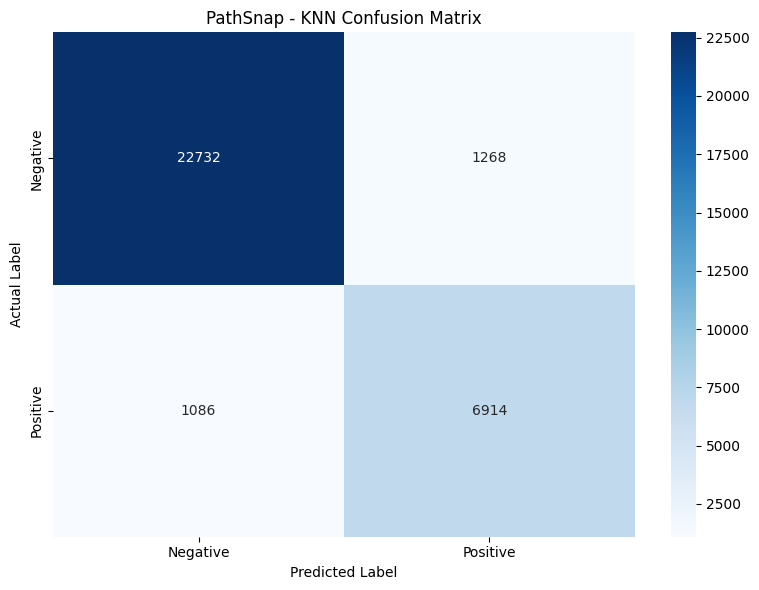

In [48]:

cm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("PathSnap - KNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


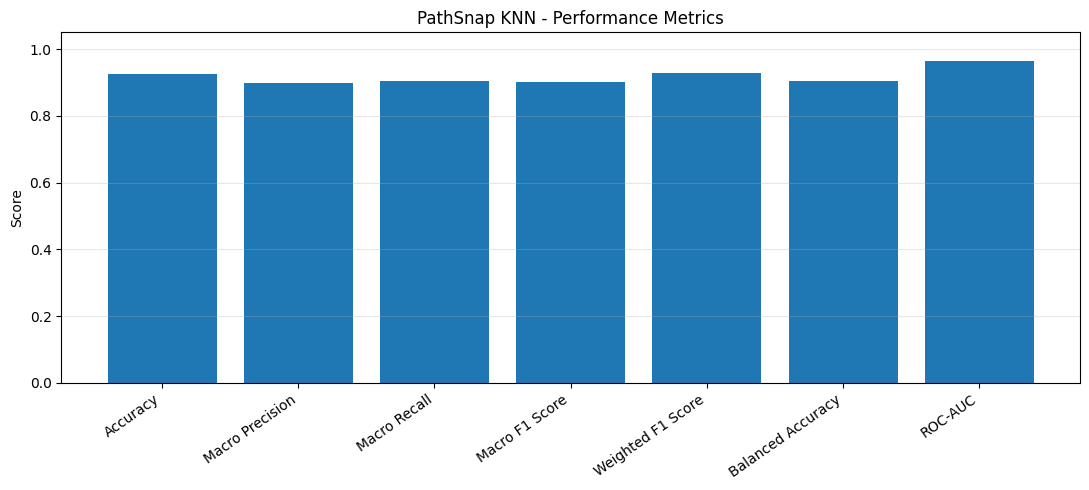

In [49]:

plot_metrics = metrics[
    metrics["Evaluation Metric"] != "Log Loss"
]

plt.figure(figsize=(11, 5))

plt.bar(
    plot_metrics["Evaluation Metric"],
    plot_metrics["Score"]
)

plt.title("PathSnap KNN - Performance Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [50]:

metrics.to_csv(
    "KNN_Final_Evaluation_Metrics.csv",
    index=False
)

fold_results.to_csv(
    "KNN_Fold_Wise_Performance.csv",
    index=False
)

pd.DataFrame({
    "Actual": y.to_numpy(),
    "Predicted": oof_predictions,
    "Positive_Probability": oof_probabilities
}).to_csv(
    "KNN_Out_Of_Fold_Predictions.csv",
    index=False
)

print("All evaluation reports saved successfully!")


All evaluation reports saved successfully!


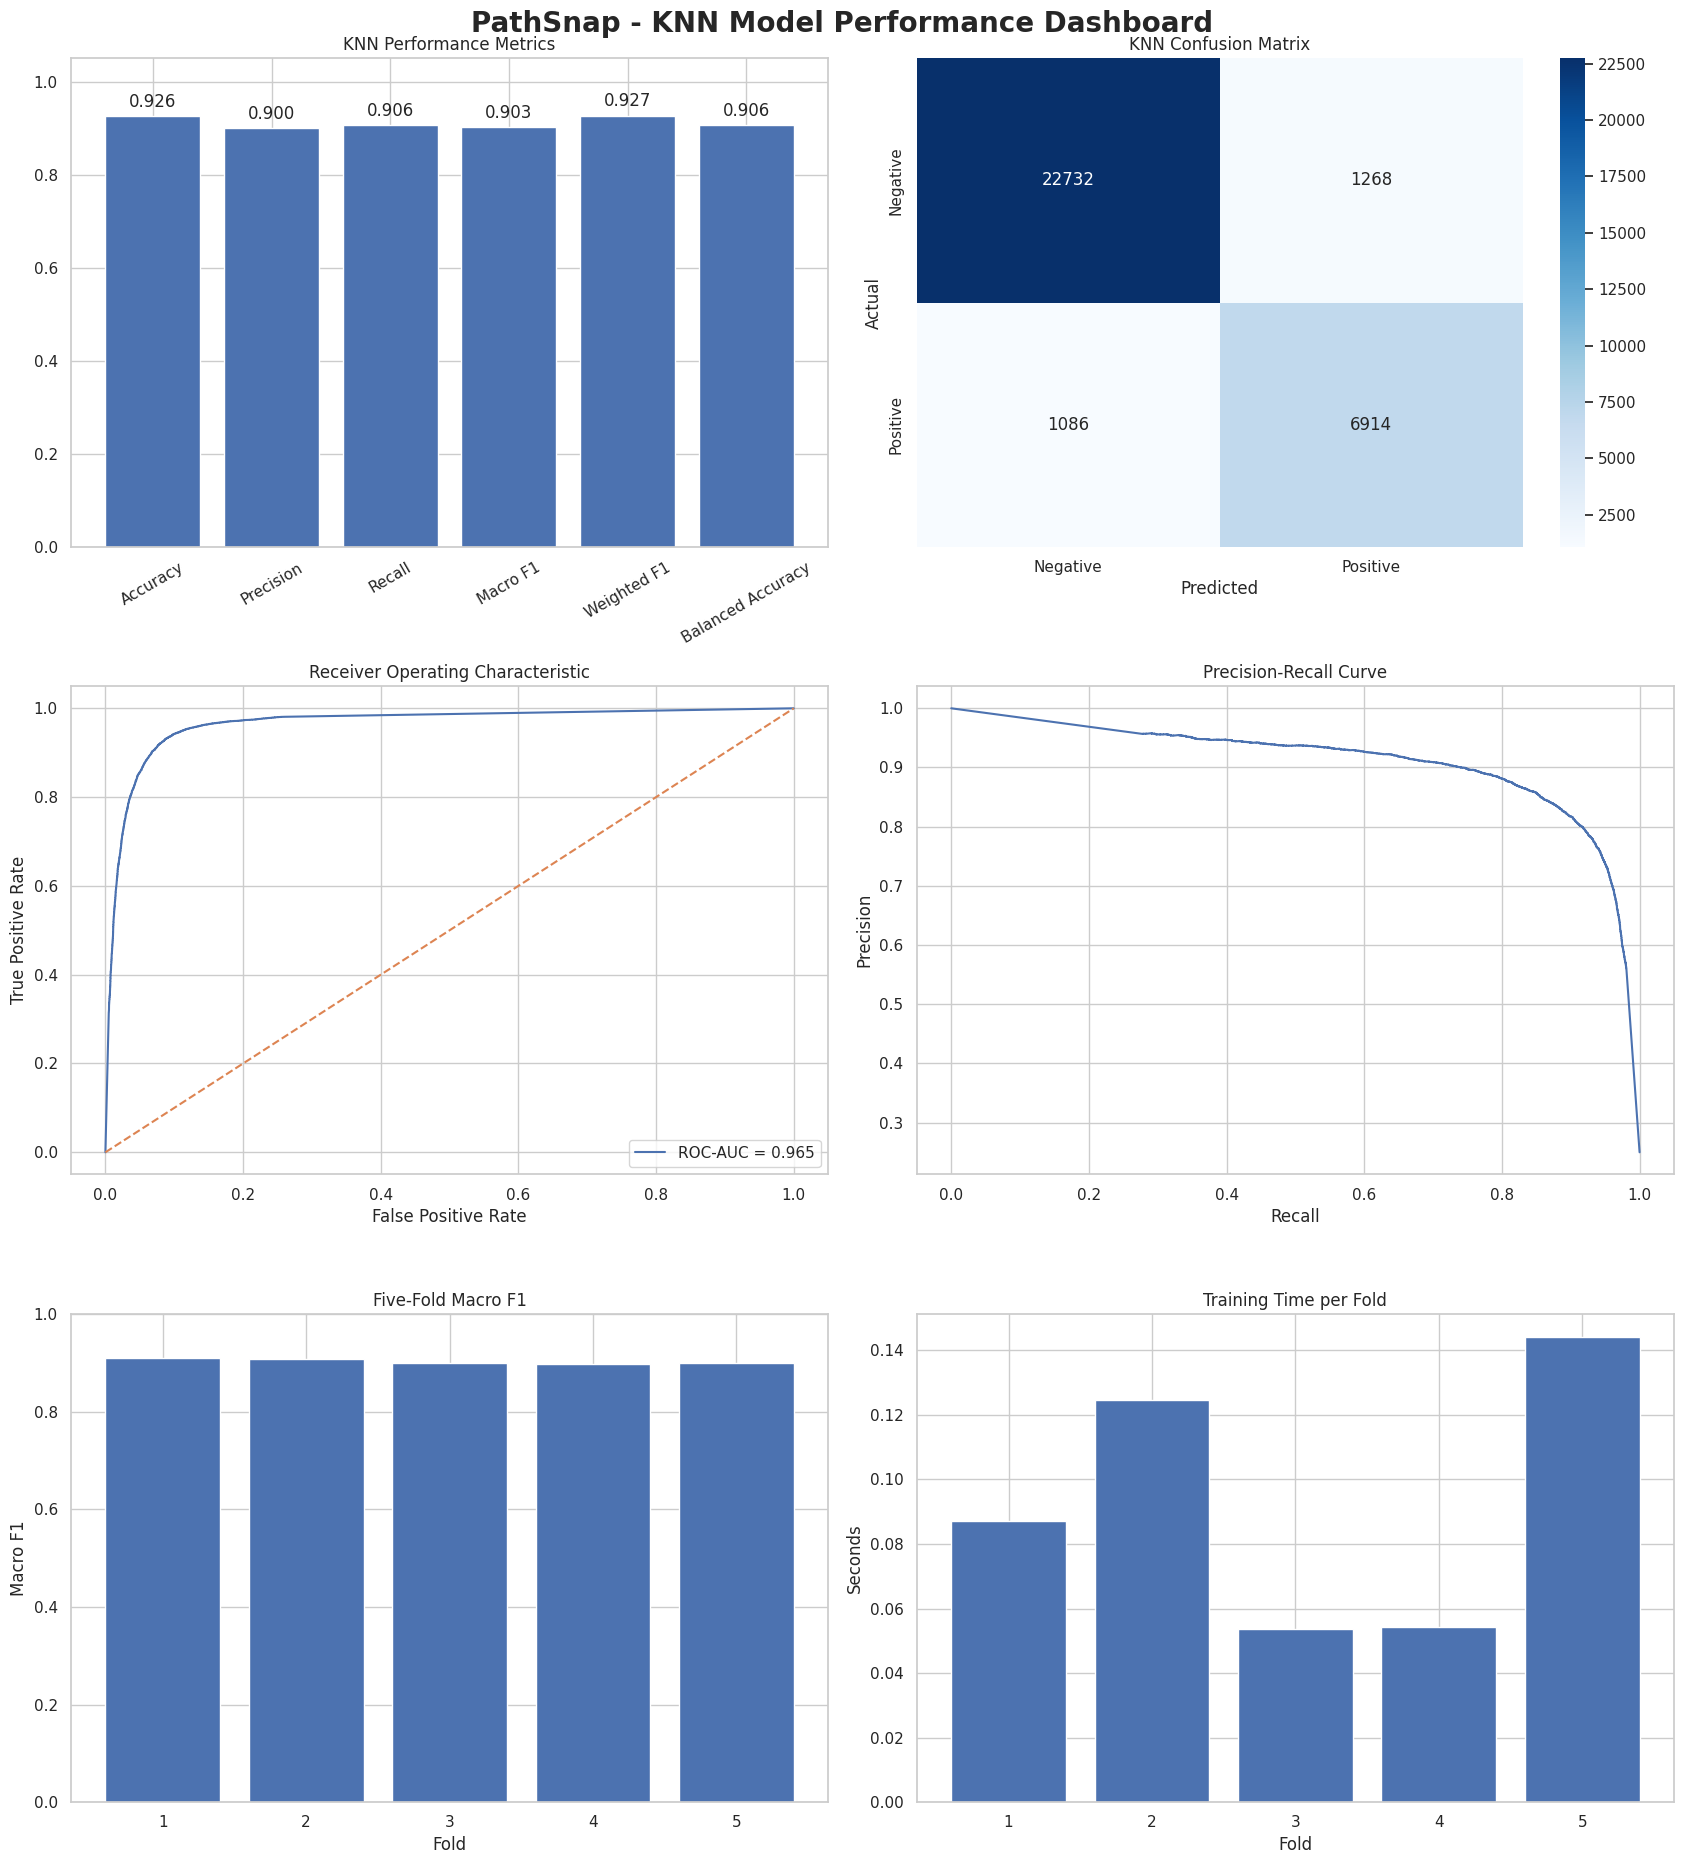

ROC-AUC: 0.9652
Log Loss: 0.2793
Dashboard generated successfully!


In [51]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

sns.set_theme(style="whitegrid")

# Create a 3 x 2 dashboard
fig, axes = plt.subplots(3, 2, figsize=(17, 19))

# GRAPH 1: Performance metrics
metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1",
    "Weighted F1",
    "Balanced Accuracy"
]

metric_values = [
    accuracy,
    precision,
    recall,
    macro_f1,
    weighted_f1,
    balanced_acc
]

axes[0, 0].bar(metric_names, metric_values)
axes[0, 0].set_title("KNN Performance Metrics")
axes[0, 0].set_ylim(0, 1.05)
axes[0, 0].tick_params(axis="x", rotation=30)

for i, value in enumerate(metric_values):
    axes[0, 0].text(i, value + 0.02, f"{value:.3f}",
                    ha="center")

# GRAPH 2: Confusion matrix
cm = confusion_matrix(y, oof_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    ax=axes[0, 1]
)

axes[0, 1].set_title("KNN Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# GRAPH 3: ROC curve
fpr, tpr, thresholds = roc_curve(
    y, oof_probabilities
)

roc_auc = auc(fpr, tpr)

axes[1, 0].plot(
    fpr, tpr,
    label=f"ROC-AUC = {roc_auc:.3f}"
)

axes[1, 0].plot(
    [0, 1], [0, 1], linestyle="--"
)

axes[1, 0].set_title("Receiver Operating Characteristic")
axes[1, 0].set_xlabel("False Positive Rate")
axes[1, 0].set_ylabel("True Positive Rate")
axes[1, 0].legend()

# GRAPH 4: Precision-Recall curve
pr_precision, pr_recall, _ = precision_recall_curve(
    y, oof_probabilities
)

axes[1, 1].plot(
    pr_recall, pr_precision
)

axes[1, 1].set_title("Precision-Recall Curve")
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_ylabel("Precision")

# GRAPH 5: Fold-wise Macro F1
axes[2, 0].bar(
    fold_results["Fold"].astype(str),
    fold_results["Macro F1"]
)

axes[2, 0].set_title("Five-Fold Macro F1")
axes[2, 0].set_xlabel("Fold")
axes[2, 0].set_ylabel("Macro F1")
axes[2, 0].set_ylim(0, 1)

# GRAPH 6: Training time
axes[2, 1].bar(
    fold_results["Fold"].astype(str),
    fold_results["Training Time"]
)

axes[2, 1].set_title("Training Time per Fold")
axes[2, 1].set_xlabel("Fold")
axes[2, 1].set_ylabel("Seconds")

plt.suptitle(
    "PathSnap - KNN Model Performance Dashboard",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc, 4))
print("Log Loss:", round(loss, 4))
print("Dashboard generated successfully!")


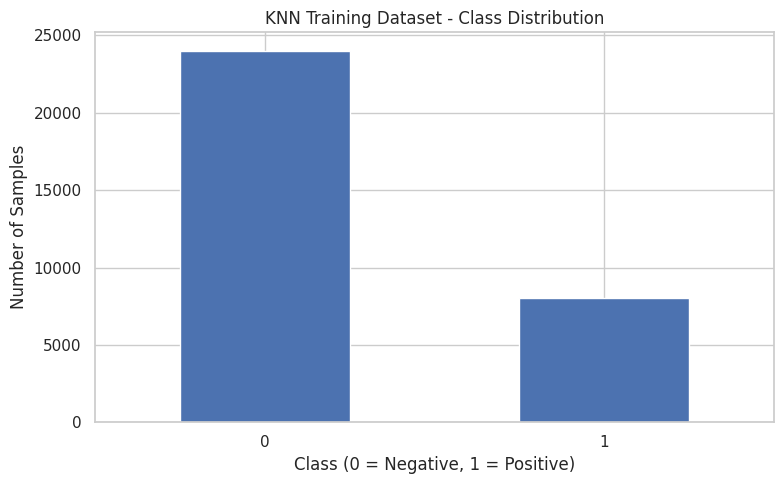

In [52]:

plt.figure(figsize=(8, 5))

knn_df["label"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("KNN Training Dataset - Class Distribution")
plt.xlabel("Class (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


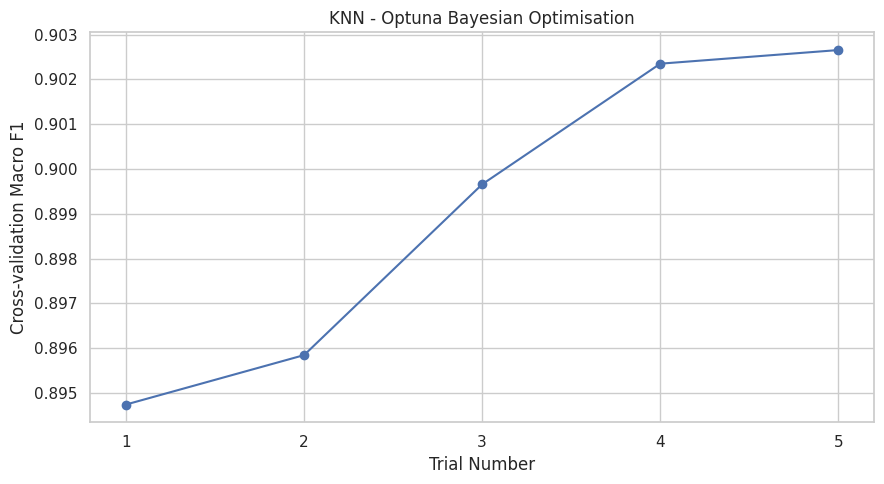

In [53]:

plt.figure(figsize=(9, 5))

trial_numbers = [
    trial.number + 1 for trial in study.trials
]

trial_scores = [
    trial.value for trial in study.trials
]

plt.plot(
    trial_numbers,
    trial_scores,
    marker="o"
)

plt.title("KNN - Optuna Bayesian Optimisation")
plt.xlabel("Trial Number")
plt.ylabel("Cross-validation Macro F1")
plt.xticks(trial_numbers)
plt.tight_layout()
plt.show()


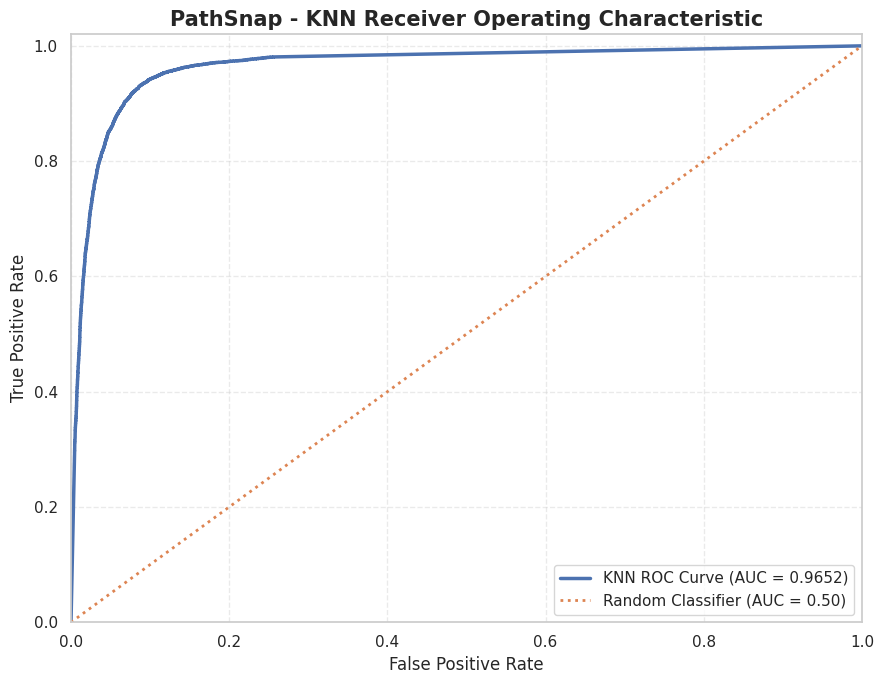

ROC-AUC Score: 0.9652
ROC graph saved successfully!


In [54]:

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import roc_curve, auc, roc_auc_score

# Use actual out-of-fold predictions
fpr, tpr, thresholds = roc_curve(
    y,
    oof_probabilities
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))

# Actual KNN ROC curve
plt.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=f"KNN ROC Curve (AUC = {roc_auc:.4f})"
)

# Straight dotted diagonal reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":",
    linewidth=2,
    label="Random Classifier (AUC = 0.50)"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "PathSnap - KNN Receiver Operating Characteristic",
    fontsize=15,
    fontweight="bold"
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="lower right", fontsize=11)

plt.tight_layout()

plt.savefig(
    "PathSnap_KNN_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))
print("ROC graph saved successfully!")
